In [3]:
from google.colab import userdata
from google.colab import drive
import urllib.request
import pandas as pd
import os

# Configurações do GIT
token = userdata.get('GITHUB_TOKEN')
usuario = "muriloklein"
repo = "tcc"

if not os.path.exists("/content/tcc"):
    !git clone https://{token}@github.com/{usuario}/{repo}.git
%cd /content/tcc

# !git config --global user.email "eu.murilok@gmail.com"
# !git config --global user.name "Murilo Klein"

# !pip install imbalanced-learn --quiet

Cloning into 'tcc'...
remote: Enumerating objects: 54, done.
remote: Counting objects: 100% (54/54), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 54 (delta 21), reused 46 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (54/54), 62.64 KiB | 7.83 MiB/s, done.
Resolving deltas: 100% (21/21), done.
/content/tcc


In [4]:
# Montar o Google Drive
drive.mount('/content/drive')

# Cria a pasta onde os dados brutos vão ficar (se ainda não existir)
DADOS_DIR = "/content/drive/MyDrive/TCC/dados/raw"
os.makedirs(DADOS_DIR, exist_ok=True)

print(f"Pasta de dados pronta em: {DADOS_DIR}")

Mounted at /content/drive
Pasta de dados pronta em: /content/drive/MyDrive/TCC/dados/raw


In [5]:
# Baixar os arquivos conn.log.labeled dos cenários escolhidos
cenarios = {
    "capture_34_1_DDoS_PortScan": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-IoT-Malware-Capture-34-1/bro/conn.log.labeled"
    ),
    "capture_9_1_PortScan": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-IoT-Malware-Capture-9-1/bro/conn.log.labeled"
    ),
    "capture_36_1_Okiru": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-IoT-Malware-Capture-36-1/bro/conn.log.labeled"
    ),
    "capture_4_1_Benign_Honeypot": (
        "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
        "IndividualScenarios/CTU-Honeypot-Capture-4-1/bro/conn.log.labeled"
    ),
    "capture_5_1_Benign_Honeypot": (
      "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
      "IndividualScenarios/CTU-Honeypot-Capture-5-1/bro/conn.log.labeled"
    ),
    "capture_7_1_Benign_Honeypot": (
      "https://mcfp.felk.cvut.cz/publicDatasets/IoT-23-Dataset/"
      "IndividualScenarios/CTU-Honeypot-Capture-7-1/Somfy-01/bro/conn.log.labeled"
    ),
}

for nome, url in cenarios.items():
    destino = os.path.join(DADOS_DIR, f"{nome}.log.labeled")

    # Se baixado antes, não baixa de novo
    if os.path.exists(destino):
        print(f"[OK] {nome} já existe, pulando download.")
        continue

    print(f"Baixando {nome}...")
    try:
        urllib.request.urlretrieve(url, destino)
        print(f"[OK] {nome} salvo em {destino}")
    except Exception as e:
        print(f"[ERRO] Falha ao baixar {nome}: {e}")


[OK] capture_34_1_DDoS_PortScan já existe, pulando download.
[OK] capture_9_1_PortScan já existe, pulando download.
[OK] capture_36_1_Okiru já existe, pulando download.
[OK] capture_4_1_Benign_Honeypot já existe, pulando download.
[OK] capture_5_1_Benign_Honeypot já existe, pulando download.
[OK] capture_7_1_Benign_Honeypot já existe, pulando download.


In [6]:
# Entender o cabeçalho do arquivo antes de carregar
caminho_exemplo = os.path.join(DADOS_DIR, "capture_34_1_DDoS_PortScan.log.labeled")

with open(caminho_exemplo, "r") as f:
    for i, linha in enumerate(f):
        print(f"{i}: {linha.strip()}")
        if i > 10:  # só as 10 primeiras linhas, o suficiente pra ver o cabeçalho
            break

# "#fields" -> lista os nomes das colunas
# "#separator \x09" -> confirma que é tab

0: #separator \x09
1: #set_separator	,
2: #empty_field	(empty)
3: #unset_field	-
4: #path	conn
5: #open	2019-03-15-14-50-49
6: #fields	ts	uid	id.orig_h	id.orig_p	id.resp_h	id.resp_p	proto	service	duration	orig_bytes	resp_bytes	conn_state	local_orig	local_resp	missed_bytes	history	orig_pkts	orig_ip_bytes	resp_pkts	resp_ip_bytes	tunnel_parents	label	det_label
7: #types	time	string	addr	port	addr	port	enum	string	interval	count	count	string	bool	bool	count	string	count	count	count	count	set[string]	string	string
8: 1545403816.962094	CrDn63WjJEmrWGjqf	192.168.1.195	41040	185.244.25.235	80	tcp	-	3.139211	0	0	S0	-	-	0	S	3	180	0	0	-	Benign	-
9: 1545403824.181240	CY9lJW3gh1Eje4usP6	192.168.1.195	41040	185.244.25.235	80	tcp	-	-	-	-	S0	-	-	0	S	1	60	0	0	-	Benign	-
10: 1545403832.341331	CcFXLynukEDnUlvgl	192.168.1.195	41040	185.244.25.235	80	tcp	-	-	-	-	S0	-	-	0	S	1	60	0	0	-	Benign	-
11: 1545403848.981338	CDrkrSobGYxHhYfth	192.168.1.195	41040	185.244.25.235	80	tcp	http	1.477656	149	128252	SF	-	-	2

In [7]:
# Carregar o arquivo corretamente com pandas (VERSÃO OTIMIZADA em memória)
import gc

colunas_usadas = [
    "id.orig_p", "id.resp_p", "proto", "service", "duration",
    "orig_bytes", "resp_bytes", "conn_state", "local_orig", "local_resp",
    "missed_bytes", "history", "orig_pkts", "orig_ip_bytes",
    "resp_pkts", "resp_ip_bytes", "label", "detailed-label"
]

# Nomes de coluna padrão do conn.log do Zeek + as 2 colunas extras do IoT-23.
colunas_completas = [
    "ts", "uid", "id.orig_h", "id.orig_p", "id.resp_h", "id.resp_p",
    "proto", "service", "duration", "orig_bytes", "resp_bytes",
    "conn_state", "local_orig", "local_resp", "missed_bytes",
    "history", "orig_pkts", "orig_ip_bytes", "resp_pkts", "resp_ip_bytes",
    "tunnel_parents", "label", "detailed-label"
]

caminho_34 = os.path.join(DADOS_DIR, "capture_34_1_DDoS_PortScan.log.labeled")
caminho_36 = os.path.join(DADOS_DIR, "capture_36_1_Okiru.log.labeled")
caminho_5_1 = os.path.join(DADOS_DIR, "capture_5_1_Benign_Honeypot.log.labeled")
caminho_4_1 = os.path.join(DADOS_DIR, "capture_4_1_Benign_Honeypot.log.labeled")
caminho_9_1 = os.path.join(DADOS_DIR, "capture_9_1_PortScan.log.labeled")
caminho_7_1 = os.path.join(DADOS_DIR, "capture_7_1_Benign_Honeypot.log.labeled")

# dtype otimizado: colunas repetitivas viram 'category' (muito mais leve que string/object)
# e colunas numéricas usam tipos menores (int32 em vez de int64/float64)
dtype_otimizado = {
    "proto": "category",
    "service": "category",
    "conn_state": "category",
    "local_orig": "category",
    "local_resp": "category",
    "history": "category",
    "label": "category",
    "detailed-label": "category",
    "id.orig_p": "int32",
    "id.resp_p": "int32",
    "missed_bytes": "int32",
    "orig_pkts": "int32",
    "orig_ip_bytes": "int32",
    "resp_pkts": "int32",
    "resp_ip_bytes": "int32",
}

config = {
    "sep": r"\s+", # colunas separadas por espaço/tab (o header usa \x09; Mas as últimas colunas às vezes vêm separadas por espaço simples - \s+ lida com os dois casos)
    "comment": "#", # ignora todas as linhas de cabeçalho que começam com #
    "header": None, # não tem cabeçalho "normal" de CSV, vamos nomear na mão
    "names": colunas_completas, # nomes de todas as colunas do arquivo
    "usecols": colunas_usadas, # mas só carrega estas na memória
    "na_values": "-", # o Zeek usa "-" para representar valor ausente
    "dtype": dtype_otimizado, # <-- reduz drasticamente o uso de RAM
}


In [8]:
# Função utilitária: carrega um cenário já otimizado e imprime um resumo
def carregar_cenario(caminho, nome_origem, filtro_excluir_detailed_label=None):
    df = pd.read_csv(caminho, **config)

    # 'label' e 'detailed-label' já vêm como category; padroniza para minúsculo
    df["label"] = df["label"].astype("string").str.lower().astype("category")
    df["detailed-label"] = df["detailed-label"].astype("string").str.lower().astype("category")

    if filtro_excluir_detailed_label is not None:
        df = df[df["detailed-label"] != filtro_excluir_detailed_label]

    df["origem_cenario"] = nome_origem

    print(f"Formato do DataFrame ({nome_origem}): {df.shape}")
    print(f"Uso de memória: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    print(df["label"].value_counts())
    print("-" * 60)

    return df


In [9]:
df_34 = carregar_cenario(caminho_34, "capture_34_1")


Formato do DataFrame (capture_34_1): (23145, 19)
Uso de memória: 2.67 MB
label
malicious    21222
benign        1923
Name: count, dtype: int64
------------------------------------------------------------


In [10]:
df_36 = carregar_cenario(caminho_36, "capture_36_1", filtro_excluir_detailed_label="okiru-attack")


Formato do DataFrame (capture_36_1): (13645095, 19)
Uso de memória: 1678.68 MB
label
malicious    13642432
benign           2663
Name: count, dtype: int64
------------------------------------------------------------


In [11]:
df_5_1 = carregar_cenario(caminho_5_1, "capture_5_1")


Formato do DataFrame (capture_5_1): (1374, 19)
Uso de memória: 0.16 MB
label
benign    1374
Name: count, dtype: int64
------------------------------------------------------------


In [12]:
df_4_1 = carregar_cenario(caminho_4_1, "capture_4_1")


Formato do DataFrame (capture_4_1): (452, 19)
Uso de memória: 0.05 MB
label
benign    452
Name: count, dtype: int64
------------------------------------------------------------


In [13]:
df_9_1 = carregar_cenario(caminho_9_1, "capture_9_1")


Formato do DataFrame (capture_9_1): (6378293, 19)
Uso de memória: 729.94 MB
label
malicious    6355745
benign         22548
Name: count, dtype: int64
------------------------------------------------------------


In [14]:
df_7_1 = carregar_cenario(caminho_7_1, "capture_7_1")

Formato do DataFrame (capture_7_1): (130, 19)
Uso de memória: 0.02 MB
label
benign    130
Name: count, dtype: int64
------------------------------------------------------------


In [15]:
# Une todos em um único DataFrame, empilhando as linhas
# (a coluna 'origem_cenario' já foi adicionada dentro de carregar_cenario)
df_completo = pd.concat(
    [df_34, df_36, df_9_1, df_4_1, df_5_1, df_7_1],
    ignore_index=True   # gera um novo índice sequencial, em vez de repetir os índices originais
)

# Libera a memória dos DataFrames individuais, já que agora estão duplicados dentro de df_completo
del df_34, df_36, df_9_1, df_4_1, df_5_1, df_7_1
gc.collect()

print(f"Formato final: {df_completo.shape}")
print(f"Uso de memória total: {df_completo.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(df_completo["origem_cenario"].value_counts())
print(df_completo["label"].value_counts())


Formato final: (20048489, 19)
Uso de memória total: 7992.63 MB
origem_cenario
capture_36_1    13645095
capture_9_1      6378293
capture_34_1       23145
capture_5_1         1374
capture_4_1          452
capture_7_1          130
Name: count, dtype: int64
label
malicious    20019399
benign          29090
Name: count, dtype: Int64


In [16]:
# Cria uma coluna auxiliar só para a amostragem,
# e para linhas benignas (que têm detailed-label vazio) usa "benign" como rótulo do grupo
df_completo["classe_amostra"] = (
    df_completo["detailed-label"]
    .astype("string")
    .fillna("benign")
)

print(df_completo["classe_amostra"].value_counts())

classe_amostra
okiru                        13626744
partofahorizontalportscan     6355867
benign                          29090
c&c-heartbeat                   15688
ddos                            14394
c&c                              6706
Name: count, dtype: Int64


In [17]:
CAP_POR_CLASSE = 20000
RANDOM_STATE = 42
CLASSES_SEM_TETO = {"benign"}   # não corta o benigno, mesmo acima do teto

grupos_amostrados = []
for classe, grupo in df_completo.groupby("classe_amostra", observed=True):
    if classe not in CLASSES_SEM_TETO and len(grupo) > CAP_POR_CLASSE:
        grupo = grupo.sample(n=CAP_POR_CLASSE, random_state=RANDOM_STATE)
    grupos_amostrados.append(grupo)

df_amostrado = pd.concat(grupos_amostrados, ignore_index=True)
df_amostrado = df_amostrado.drop(columns=["classe_amostra"])

del df_completo
import gc; gc.collect()

print(f"Formato após amostragem: {df_amostrado.shape}")
print(df_amostrado["detailed-label"].value_counts(dropna=False))
print(f"Uso de memória: {df_amostrado.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

Formato após amostragem: (105878, 19)
detailed-label
<NA>                         29090
partofahorizontalportscan    20000
okiru                        20000
c&c-heartbeat                15688
ddos                         14394
c&c                           6706
Name: count, dtype: Int64
Uso de memória: 42.09 MB


In [18]:
# Checkpoint para salvar os dados

PROCESSED_DIR = "/content/drive/MyDrive/TCC/dados/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

caminho_checkpoint = os.path.join(PROCESSED_DIR, "dataset_amostrado_v1.parquet")
df_amostrado.to_parquet(caminho_checkpoint, index=False)

print(f"Checkpoint salvo em: {caminho_checkpoint}")
print(f"Tamanho do arquivo: {os.path.getsize(caminho_checkpoint) / 1024**2:.2f} MB")

Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_amostrado_v1.parquet
Tamanho do arquivo: 0.72 MB


In [19]:
# import pandas as pd
# import os

caminho_checkpoint = os.path.join(PROCESSED_DIR, "dataset_amostrado_v1.parquet")
df_amostrado = pd.read_parquet(caminho_checkpoint)

print(f"Formato recarregado: {df_amostrado.shape}")
print(df_amostrado["detailed-label"].value_counts(dropna=False))

Formato recarregado: (105878, 19)
detailed-label
<NA>                         29090
partofahorizontalportscan    20000
okiru                        20000
c&c-heartbeat                15688
ddos                         14394
c&c                           6706
Name: count, dtype: Int64


In [20]:
# Tratamento de valores ausentes

# Descarta colunas 100% vazias
df_amostrado = df_amostrado.drop(columns=["local_orig", "local_resp"])

# Cria indicadores antes de preencher
for col in ["duration", "orig_bytes", "resp_bytes"]:
    df_amostrado[f"{col}_ausente"] = df_amostrado[col].isna()

# Preenche os numéricos ausentes com 0
df_amostrado[["duration", "orig_bytes", "resp_bytes"]] = (
    df_amostrado[["duration", "orig_bytes", "resp_bytes"]].fillna(0)
)

# Preenche categóricas ausentes com rótulo explícito
for col in ["service", "history"]:
    if df_amostrado[col].dtype.name == "category":
        df_amostrado[col] = df_amostrado[col].cat.add_categories(["desconhecido"])
    df_amostrado[col] = df_amostrado[col].fillna("desconhecido")

# Confirma que só restou NaN em detailed-label (esperado, são as linhas benignas)
print(df_amostrado.isna().sum())

id.orig_p                 0
id.resp_p                 0
proto                     0
service                   0
duration                  0
orig_bytes                0
resp_bytes                0
conn_state                0
missed_bytes              0
history                   0
orig_pkts                 0
orig_ip_bytes             0
resp_pkts                 0
resp_ip_bytes             0
label                     0
detailed-label        29090
origem_cenario            0
duration_ausente          0
orig_bytes_ausente        0
resp_bytes_ausente        0
dtype: int64


In [21]:
# Remove colunas redundantes identificadas na EDA (correlação = 1.00 com resp_bytes/orig_bytes)

df_amostrado = df_amostrado.drop(columns=["resp_ip_bytes", "orig_ip_bytes"])

print(f"Formato após remoção: {df_amostrado.shape}")
print(df_amostrado.columns.tolist())

Formato após remoção: (105878, 18)
['id.orig_p', 'id.resp_p', 'proto', 'service', 'duration', 'orig_bytes', 'resp_bytes', 'conn_state', 'missed_bytes', 'history', 'orig_pkts', 'resp_pkts', 'label', 'detailed-label', 'origem_cenario', 'duration_ausente', 'orig_bytes_ausente', 'resp_bytes_ausente']


In [22]:
# Outro checkpoint
caminho_checkpoint_limpo = os.path.join(PROCESSED_DIR, "dataset_limpo_v1.parquet")
df_amostrado.to_parquet(caminho_checkpoint_limpo, index=False)
print(f"Checkpoint salvo em: {caminho_checkpoint_limpo}")

Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_limpo_v1.parquet


In [23]:
colunas_categoricas = ["proto", "service", "conn_state", "history", "origem_cenario"]

for col in colunas_categoricas:
    print(f"{col}: {df_amostrado[col].nunique()} valores distintos")
    print(df_amostrado[col].value_counts().head(10))  # os 10 mais comuns
    print("-" * 60)

proto: 3 valores distintos
proto
tcp     82065
udp     20647
icmp     3166
Name: count, dtype: int64
------------------------------------------------------------
service: 6 valores distintos
service
desconhecido    100824
dns               2871
irc               1641
http               278
dhcp               177
ssl                 87
Name: count, dtype: int64
------------------------------------------------------------
conn_state: 13 valores distintos
conn_state
S0      78030
OTH     17446
SF       4216
REJ      4068
S3       1611
RSTO      205
RSTR      135
SH        106
S1         19
SHR        14
Name: count, dtype: int64
------------------------------------------------------------
history: 109 valores distintos
history
S               60983
D               17040
C               14252
Sr               4068
Dd               3597
desconhecido     3166
ShAdDaf          1477
ShR               172
ShAFf             172
ShAdDafF          143
Name: count, dtype: int64
--------------------

In [24]:
# Agrupando categorias
# Define o corte: manter categorias com pelo menos 500 ocorrências, por exemplo
LIMIAR_MINIMO = 500

contagem = df_amostrado["history"].value_counts()
categorias_frequentes = contagem[contagem >= LIMIAR_MINIMO].index.tolist()

print(f"Categorias mantidas ({len(categorias_frequentes)}): {categorias_frequentes}")
print(f"Categorias agrupadas em 'outros': {df_amostrado['history'].nunique() - len(categorias_frequentes)}")

# Aplica: quem não está na lista de frequentes vira "outros"
df_amostrado["history"] = df_amostrado["history"].astype("string")
df_amostrado["history"] = df_amostrado["history"].where(
    df_amostrado["history"].isin(categorias_frequentes),
    "outros"
)

print(df_amostrado["history"].value_counts())

Categorias mantidas (7): ['S', 'D', 'C', 'Sr', 'Dd', 'desconhecido', 'ShAdDaf']
Categorias agrupadas em 'outros': 102
history
S               60983
D               17040
C               14252
Sr               4068
Dd               3597
desconhecido     3166
ShAdDaf          1477
outros           1295
Name: count, dtype: Int64


In [25]:
# One hot encoding
colunas_para_onehot = ["proto", "service", "conn_state", "history"]

#label e detailed-label não devem passar por one-hot — eles são os alvos que o modelo vai tentar prever (y), não características de entrada (X). Da mesma forma, origem_cenario continua fora (é metadado de rastreio, não feature, como combinamos). Por isso eu não coloquei nenhum dos três na lista colunas_para_onehot — repara e confirma isso antes de rodar.

df_encoded = pd.get_dummies(
    df_amostrado,
    columns=colunas_para_onehot,
    prefix=colunas_para_onehot, # prefixo nas novas colunas, ex: proto_tcp, service_dns
    dtype="int8" # 0/1 como número pequeno, economiza memória
)

print(f"Formato antes: {df_amostrado.shape}")
print(f"Formato depois: {df_encoded.shape}")
print(df_encoded.columns.tolist())

Formato antes: (105878, 18)
Formato depois: (105878, 44)
['id.orig_p', 'id.resp_p', 'duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 'orig_pkts', 'resp_pkts', 'label', 'detailed-label', 'origem_cenario', 'duration_ausente', 'orig_bytes_ausente', 'resp_bytes_ausente', 'proto_icmp', 'proto_tcp', 'proto_udp', 'service_desconhecido', 'service_dhcp', 'service_dns', 'service_http', 'service_irc', 'service_ssl', 'conn_state_OTH', 'conn_state_REJ', 'conn_state_RSTO', 'conn_state_RSTOS0', 'conn_state_RSTR', 'conn_state_RSTRH', 'conn_state_S0', 'conn_state_S1', 'conn_state_S2', 'conn_state_S3', 'conn_state_SF', 'conn_state_SH', 'conn_state_SHR', 'history_C', 'history_D', 'history_Dd', 'history_S', 'history_ShAdDaf', 'history_Sr', 'history_desconhecido', 'history_outros']


In [26]:
# Checkpoint

caminho_checkpoint_encoded = os.path.join(PROCESSED_DIR, "dataset_encoded_v1.parquet")
df_encoded.to_parquet(caminho_checkpoint_encoded, index=False)
print(f"Checkpoint salvo em: {caminho_checkpoint_encoded}")

Checkpoint salvo em: /content/drive/MyDrive/TCC/dados/processed/dataset_encoded_v1.parquet


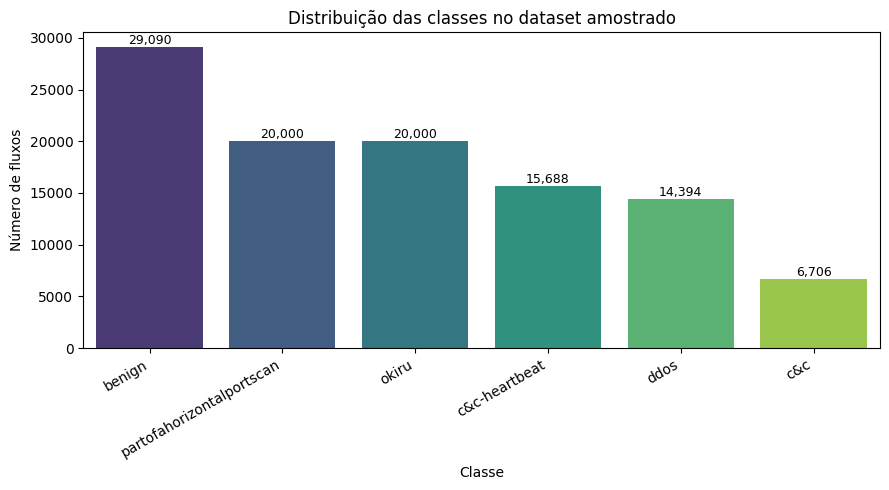

In [27]:
# Gráfico 1 — Distribuição de classes

import matplotlib.pyplot as plt
import seaborn as sns
import os

contagem_classes = df_amostrado["detailed-label"].astype("string").fillna("benign").value_counts()

plt.figure(figsize=(9, 5))
sns.barplot(x=contagem_classes.index, y=contagem_classes.values, hue=contagem_classes.index, palette="viridis", legend=False)
plt.title("Distribuição das classes no dataset amostrado")
plt.xlabel("Classe")
plt.ylabel("Número de fluxos")
plt.xticks(rotation=30, ha="right")

for i, valor in enumerate(contagem_classes.values):
    plt.text(i, valor + 300, f"{valor:,}", ha="center", fontsize=9)

plt.tight_layout()

FIGURAS_DIR = "/content/drive/MyDrive/TCC/resultados/figuras"
os.makedirs(FIGURAS_DIR, exist_ok=True)
plt.savefig(os.path.join(FIGURAS_DIR, "distribuicao_classes.png"), dpi=300, bbox_inches="tight")

plt.show()

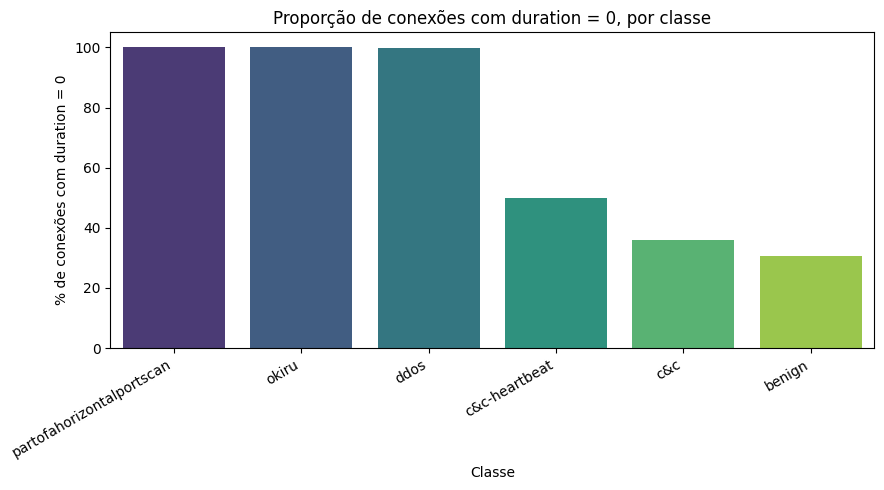

In [30]:
# Gráfico 2a — Proporção de conexões "instantâneas" (duration = 0) por classe

df_plot = df_amostrado.copy()
df_plot["classe_plot"] = df_plot["detailed-label"].astype("string").fillna("benign")

df_plot["duration_zero"] = df_plot["duration"] == 0

proporcao_zero = df_plot.groupby("classe_plot", observed=True)["duration_zero"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=proporcao_zero.index, y=proporcao_zero.values * 100, hue=proporcao_zero.index, palette="viridis", legend=False)
plt.title("Proporção de conexões com duration = 0, por classe")
plt.xlabel("Classe")
plt.ylabel("% de conexões com duration = 0")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "proporcao_duration_zero.png"), dpi=300, bbox_inches="tight")
plt.show()

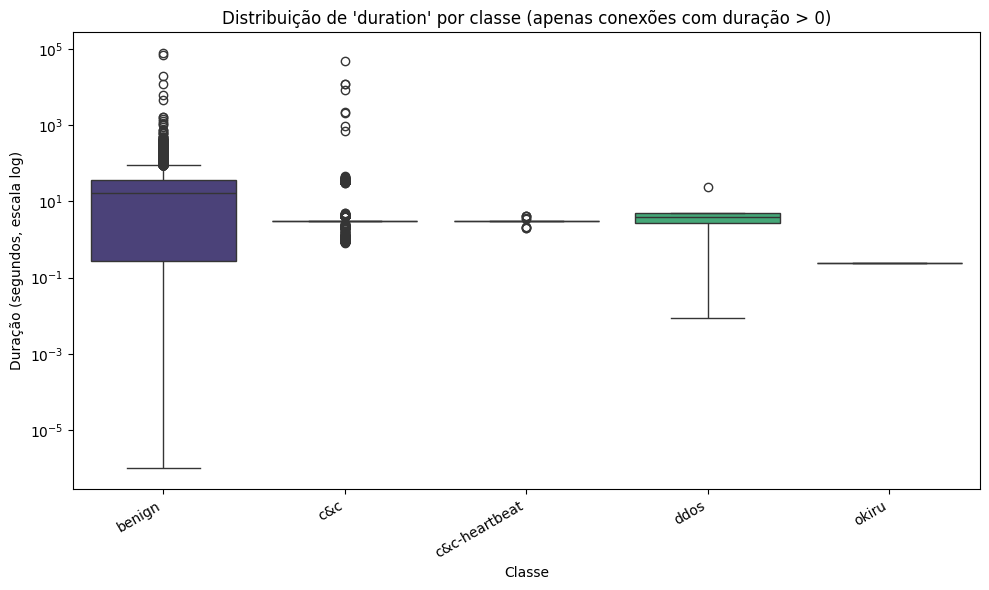

In [31]:
# Gráfico 2b — O boxplot original, mas só com quem tem duração real (> 0)

df_com_duracao = df_plot[df_plot["duration"] > 0]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_com_duracao, x="classe_plot", y="duration", hue="classe_plot", palette="viridis", legend=False)
plt.yscale("log")
plt.title("Distribuição de 'duration' por classe (apenas conexões com duração > 0)")
plt.xlabel("Classe")
plt.ylabel("Duração (segundos, escala log)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "duration_por_classe_sem_zeros.png"), dpi=300, bbox_inches="tight")
plt.show()

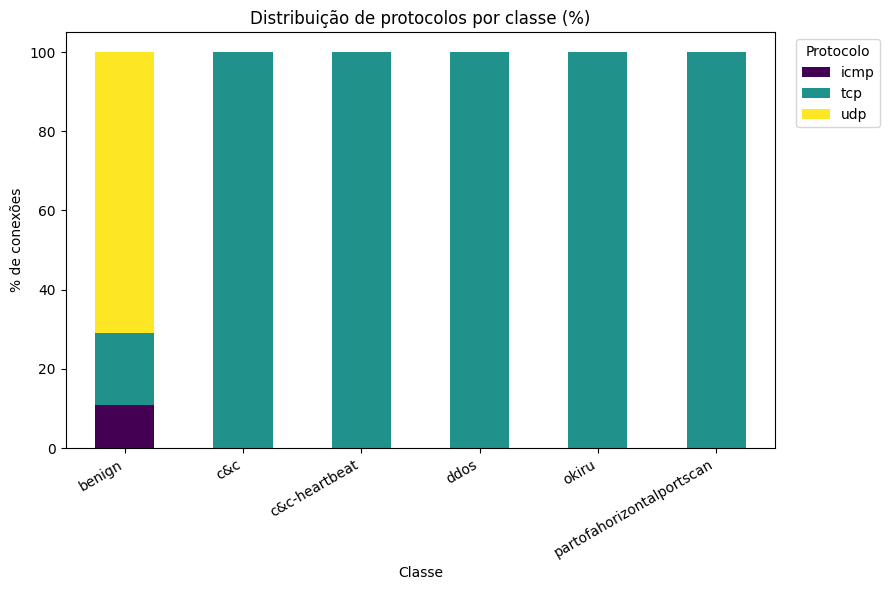

In [32]:
# Gráfico 3 — Protocolos por classe

tabela_proto = pd.crosstab(df_plot["classe_plot"], df_plot["proto"], normalize="index") * 100

plt.figure(figsize=(9, 6))
tabela_proto.plot(kind="bar", stacked=True, colormap="viridis", ax=plt.gca())
plt.title("Distribuição de protocolos por classe (%)")
plt.xlabel("Classe")
plt.ylabel("% de conexões")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Protocolo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "protocolo_por_classe.png"), dpi=300, bbox_inches="tight")
plt.show()

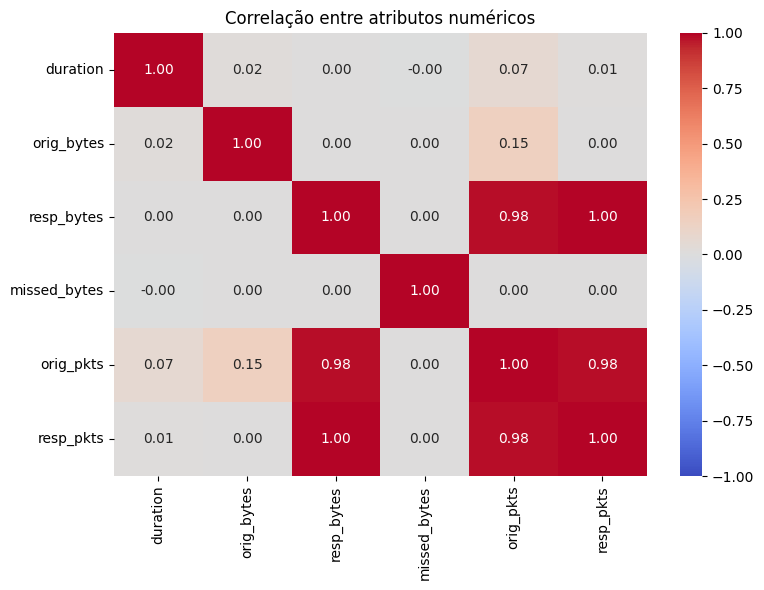

In [33]:
# Matriz de correlação

colunas_numericas = [
    "duration", "orig_bytes", "resp_bytes", "missed_bytes",
    "orig_pkts", "resp_pkts",
]

matriz_corr = df_amostrado[colunas_numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre atributos numéricos")
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS_DIR, "correlacao_numericos.png"), dpi=300, bbox_inches="tight")
plt.show()

In [37]:
# Carrega o checkpoint mais recente, se ainda não estiver em memória

df_encoded = pd.read_parquet(os.path.join(PROCESSED_DIR, "dataset_encoded_v1.parquet"))

# Colunas que NÃO são features (não entram no X):
# - label, detailed-label -> são os alvos (y), não entradas
# - origem_cenario -> metadado de rastreio, causaria vazamento (lembra da discussão?)
colunas_nao_feature = ["label", "detailed-label", "origem_cenario"]

X = df_encoded.drop(columns=colunas_nao_feature)

y_binario = df_encoded["label"]  # "benign" / "malicious"

# Para multiclasse: usa detailed-label, preenchendo os NaN (benignos) com "benign"
y_multiclasse = df_encoded["detailed-label"].astype("string").fillna("benign")

print(f"X: {X.shape}")
print(f"y_binario:\n{y_binario.value_counts()}")
print(f"\ny_multiclasse:\n{y_multiclasse.value_counts()}")

X: (105878, 41)
y_binario:
label
malicious    76788
benign       29090
Name: count, dtype: Int64

y_multiclasse:
detailed-label
benign                       29090
partofahorizontalportscan    20000
okiru                        20000
c&c-heartbeat                15688
ddos                         14394
c&c                           6706
Name: count, dtype: Int64


In [38]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_multi_treino, y_multi_teste = train_test_split(
    X, y_multiclasse,
    test_size=0.30,
    random_state=42,
    stratify=y_multiclasse   # preserva a proporção de cada classe em treino e teste
)

# Reaproveita os MESMOS índices para gerar o alvo binário correspondente
y_bin_treino = y_binario.loc[X_treino.index]
y_bin_teste = y_binario.loc[X_teste.index]

print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")
print("\nProporção multiclasse - treino:")
print(y_multi_treino.value_counts(normalize=True))
print("\nProporção multiclasse - teste:")
print(y_multi_teste.value_counts(normalize=True))

Treino: (74114, 41) | Teste: (31764, 41)

Proporção multiclasse - treino:
detailed-label
benign                       0.274752
okiru                        0.188898
partofahorizontalportscan    0.188898
c&c-heartbeat                0.148164
ddos                         0.135953
c&c                          0.063335
Name: proportion, dtype: Float64

Proporção multiclasse - teste:
detailed-label
benign                       0.274745
partofahorizontalportscan    0.188893
okiru                        0.188893
c&c-heartbeat                0.148187
ddos                          0.13594
c&c                          0.063342
Name: proportion, dtype: Float64


In [39]:
caminho_split = os.path.join(PROCESSED_DIR, "split_treino_teste_v1.parquet")

# Salva treino e teste em arquivos separados, incluindo os dois alvos
treino_completo = X_treino.copy()
treino_completo["label"] = y_bin_treino
treino_completo["detailed-label"] = y_multi_treino
treino_completo.to_parquet(os.path.join(PROCESSED_DIR, "treino_v1.parquet"), index=False)

teste_completo = X_teste.copy()
teste_completo["label"] = y_bin_teste
teste_completo["detailed-label"] = y_multi_teste
teste_completo.to_parquet(os.path.join(PROCESSED_DIR, "teste_v1.parquet"), index=False)

print("Treino e teste salvos separadamente.")

Treino e teste salvos separadamente.


In [40]:
from sklearn.preprocessing import StandardScaler

# Só as colunas numéricas "de verdade" precisam de normalização.
# As colunas 0/1 (one-hot, _ausente) já estão numa escala própria (0 ou 1) - normalizar
# elas também não é errado, mas é desnecessário e reduz a interpretabilidade.
colunas_numericas = [
    "id.orig_p", "id.resp_p", "duration", "orig_bytes",
    "resp_bytes", "missed_bytes", "orig_pkts", "resp_pkts"
]

scaler = StandardScaler()

# fit_transform no TREINO: aprende média/desvio padrão E aplica no mesmo passo
X_treino_norm = X_treino.copy()
X_treino_norm[colunas_numericas] = scaler.fit_transform(X_treino[colunas_numericas])

# transform no TESTE: usa a média/desvio JÁ aprendidos do treino, não recalcula
X_teste_norm = X_teste.copy()
X_teste_norm[colunas_numericas] = scaler.transform(X_teste[colunas_numericas])

print(X_treino_norm[colunas_numericas].describe())

          id.orig_p     id.resp_p      duration    orig_bytes    resp_bytes  \
count  7.411400e+04  7.411400e+04  7.411400e+04  7.411400e+04  7.411400e+04   
mean   2.895322e-17 -1.140393e-16 -1.509978e-18  1.018636e-19 -1.288275e-18   
std    1.000007e+00  1.000007e+00  1.000007e+00  1.000007e+00  1.000007e+00   
min   -2.134826e+00 -8.778280e-01 -2.300557e-02 -4.191287e-03 -3.731742e-03   
25%   -4.989464e-01 -8.743670e-01 -2.300557e-02 -4.191287e-03 -3.731742e-03   
50%   -1.618775e-01 -5.894007e-01 -2.300557e-02 -4.191287e-03 -3.731742e-03   
75%    8.800326e-01  7.321646e-01 -2.224986e-02 -4.191287e-03 -3.731742e-03   
max    1.447111e+00  1.957342e+00  1.810399e+02  2.718812e+02  2.722315e+02   

       missed_bytes     orig_pkts     resp_pkts  
count  7.411400e+04  7.411400e+04  7.411400e+04  
mean  -3.163763e-18  2.199055e-18  5.428729e-18  
std    1.000007e+00  1.000007e+00  1.000007e+00  
min   -1.282968e-02 -9.633259e-03 -4.202958e-03  
25%   -1.282968e-02 -7.477806e-03 -4.2

In [42]:
from imblearn.over_sampling import SMOTE

# ===== Versão SMOTE para a tarefa MULTICLASSE =====
smote_multi = SMOTE(random_state=42, k_neighbors=5)
X_treino_smote_multi, y_multi_treino_smote = smote_multi.fit_resample(X_treino_norm, y_multi_treino)

print("=== Multiclasse após SMOTE ===")
print(f"Formato: {X_treino_smote_multi.shape}")
print(y_multi_treino_smote.value_counts())

=== Multiclasse após SMOTE ===
Formato: (122178, 41)
detailed-label
c&c                          20363
okiru                        20363
partofahorizontalportscan    20363
c&c-heartbeat                20363
benign                       20363
ddos                         20363
Name: count, dtype: Int64


In [43]:
# ===== Versão SMOTE para a tarefa BINÁRIA =====
smote_bin = SMOTE(random_state=42, k_neighbors=5)
X_treino_smote_bin, y_bin_treino_smote = smote_bin.fit_resample(X_treino_norm, y_bin_treino)

print("\n=== Binário após SMOTE ===")
print(f"Formato: {X_treino_smote_bin.shape}")
print(y_bin_treino_smote.value_counts())


=== Binário após SMOTE ===
Formato: (107502, 41)
label
malicious    53751
benign       53751
Name: count, dtype: Int64


In [44]:
caminho_split = PROCESSED_DIR

# Treino ORIGINAL (sem SMOTE) - para usar com class_weight
X_treino_norm.assign(label=y_bin_treino, **{"detailed-label": y_multi_treino}) \
    .to_parquet(os.path.join(caminho_split, "treino_original_v1.parquet"), index=False)

# Treino com SMOTE - multiclasse
X_treino_smote_multi.assign(**{"detailed-label": y_multi_treino_smote}) \
    .to_parquet(os.path.join(caminho_split, "treino_smote_multiclasse_v1.parquet"), index=False)

# Treino com SMOTE - binário
X_treino_smote_bin.assign(label=y_bin_treino_smote) \
    .to_parquet(os.path.join(caminho_split, "treino_smote_binario_v1.parquet"), index=False)

# Teste (único, nunca passa por SMOTE)
X_teste_norm.assign(label=y_bin_teste, **{"detailed-label": y_multi_teste}) \
    .to_parquet(os.path.join(caminho_split, "teste_v1.parquet"), index=False)

print("Todos os conjuntos salvos.")

Todos os conjuntos salvos.
